# Modifying images

In [1]:
import numpy as np
from PIL import Image as PILimg
from IPython.display import Image, display

iRED = 0
iGREEN = 1
iBLUE = 2

## Load image

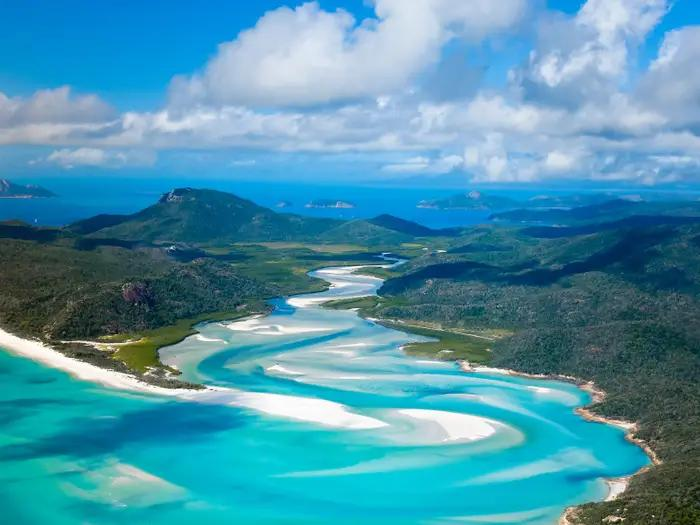

In [2]:
img = PILimg.open('./image.jpg')
img_array = np.array(img)
img_array_mod = np.array(img).copy()
display(Image(filename='./image.jpg', embed=True))

In [3]:
Nlay = img_array.shape[2]
Ncol = img_array.shape[1]
Nrow = img_array.shape[0]

r = 0
g = 0
b = 0

rnew = 0
gnew = 0
bnew = 0

def f_DOint():
    global r
    global g
    global b

    r = int(r)
    g = int(g)
    b = int(b)

def f_DOminmax():
    global rnew
    global gnew
    global bnew

    if rnew < 0: 
        rnew = 0
    if gnew < 0: 
        gnew = 0       
    if bnew < 0: 
        bnew = 0 

    if rnew > 255: 
        rnew = 255
    if gnew > 255: 
        gnew = 255       
    if bnew > 255: 
        bnew = 255 

# Demos: 

## swap color channels

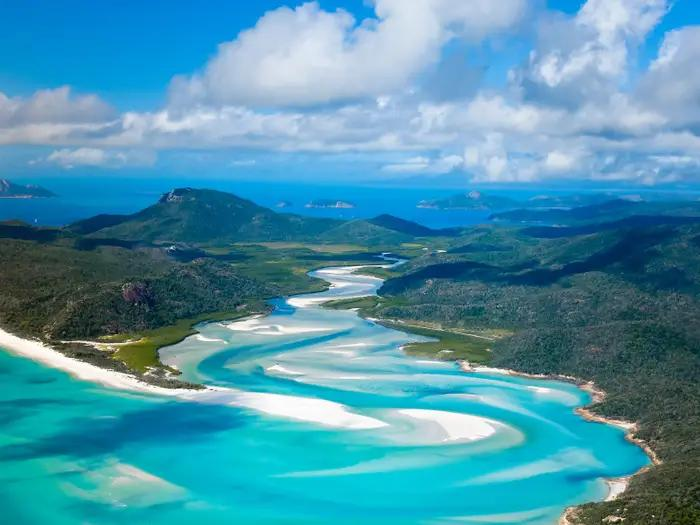

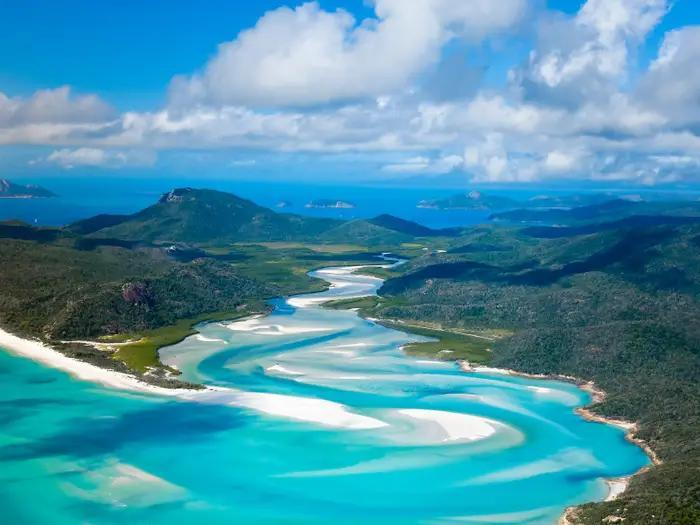

In [4]:
# make a new rgb array by copying the one corresponding to the original image
img_array_mod = img_array.copy()

#loop over rows
for indrow in range(0,Nrow):
    #loop over columns
    for indcol in range(0,Ncol):
        # get red, green, blue of the current pixel
        r = img_array[indrow,indcol,iRED]
        g = img_array[indrow,indcol,iGREEN]
        b = img_array[indrow,indcol,iBLUE]

        # set new r,g,b values through some method
        rnew = r
        gnew =g
        bnew = b

        #assign new values to the new array (ie, new image)
        img_array_mod[indrow,indcol,iRED] = rnew
        img_array_mod[indrow,indcol,iGREEN] = gnew
        img_array_mod[indrow,indcol,iBLUE] = bnew

image_new = PILimg.fromarray(img_array_mod,mode='RGB')
image_new.save("image_new.jpg")
display(Image(filename='./image.jpg', embed=True))
display(Image(filename='./image_new.jpg', embed=True))

## color inverse

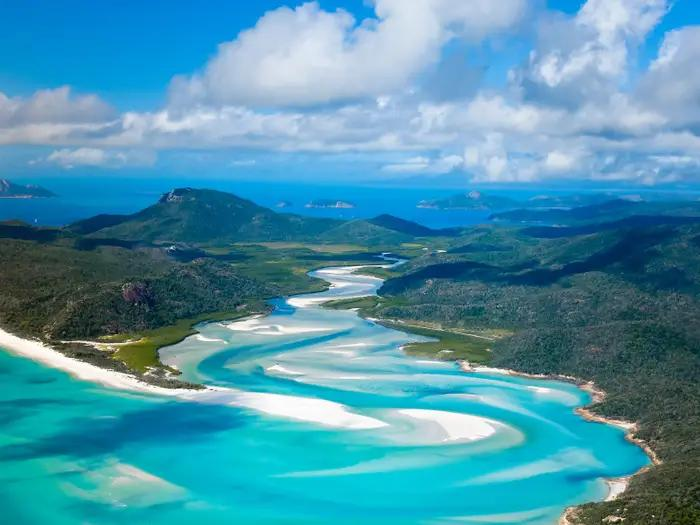

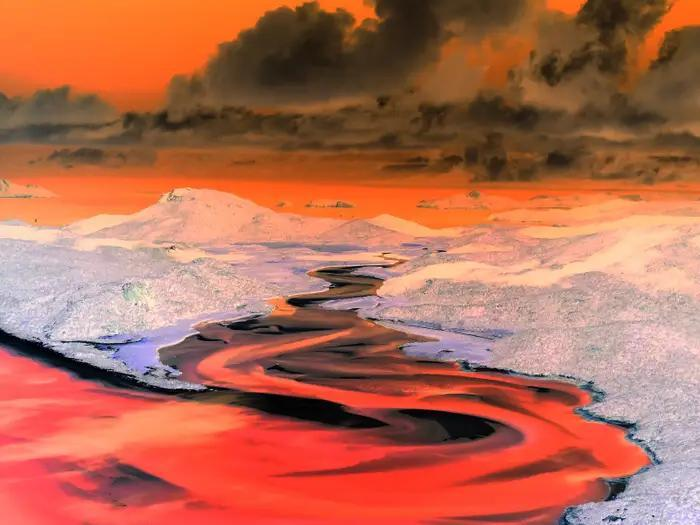

In [5]:
img_array_mod = img_array.copy()

#loop over rows
for indrow in range(0,Nrow):
    #loop over columns
    for indcol in range(0,Ncol):
        # get red, green, blue of the current pixel
        r = img_array[indrow,indcol,iRED]
        g = img_array[indrow,indcol,iGREEN]
        b = img_array[indrow,indcol,iBLUE]

        rnew = 255 - r
        gnew = 255 - g
        bnew = 255 - b
        
        img_array_mod[indrow,indcol,iRED] = rnew
        img_array_mod[indrow,indcol,iGREEN] = gnew
        img_array_mod[indrow,indcol,iBLUE] = bnew

image_new = PILimg.fromarray(img_array_mod,mode='RGB')
image_new.save("image_new.jpg")
display(Image(filename='./image.jpg', embed=True))
display(Image(filename='./image_new.jpg', embed=True))

# Change by luminosity

## set to black if below brightness threshold

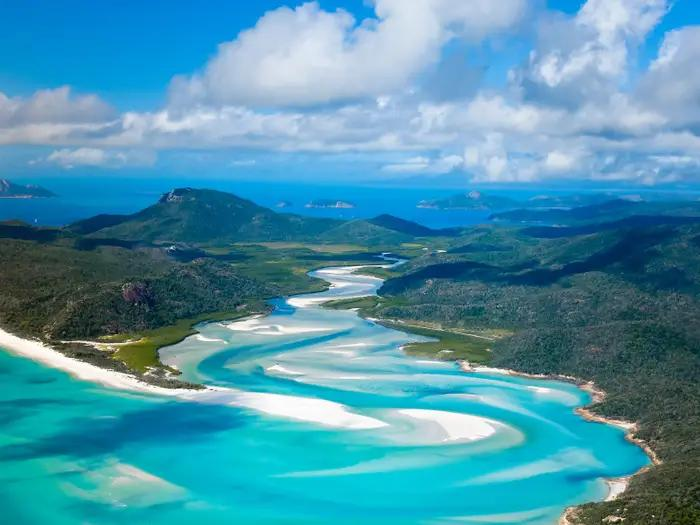

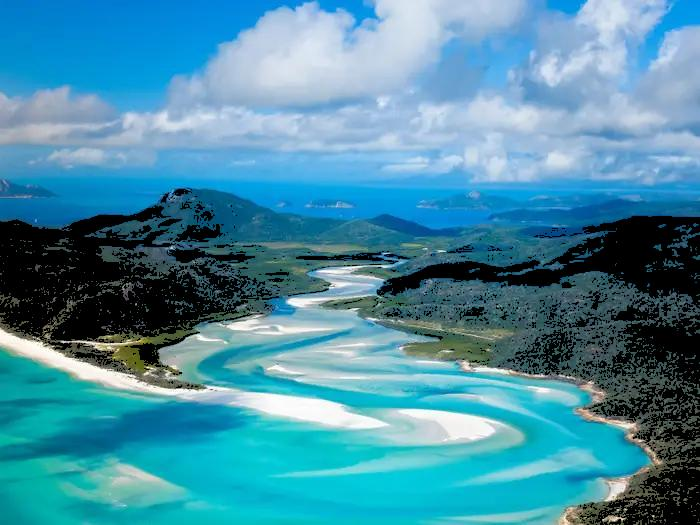

In [6]:
img_array_mod = img_array.copy()

for indrow in range(0,Nrow):
    for indcol in range(0,Ncol):
        r = img_array[indrow,indcol,0]
        g = img_array[indrow,indcol,1]
        b = img_array[indrow,indcol,2]
       
        lum = int(r) + int(g) + int(b)
        
        if lum < 200 :
            rnew = 0
            gnew = 0
            bnew = 0
        else:
            rnew = r
            gnew = g
            bnew = b
        
            
        img_array_mod[indrow,indcol,iRED] = rnew
        img_array_mod[indrow,indcol,iGREEN] = gnew
        img_array_mod[indrow,indcol,iBLUE] = bnew

image_new = PILimg.fromarray(img_array_mod,mode='RGB')
image_new.save("image_new.jpg")
display(Image(filename='./image.jpg', embed=True))
display(Image(filename='./image_new.jpg', embed=True))

## set to another color

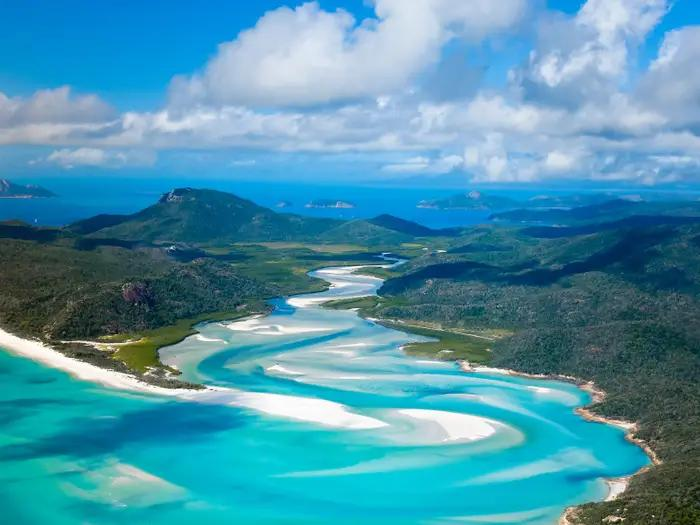

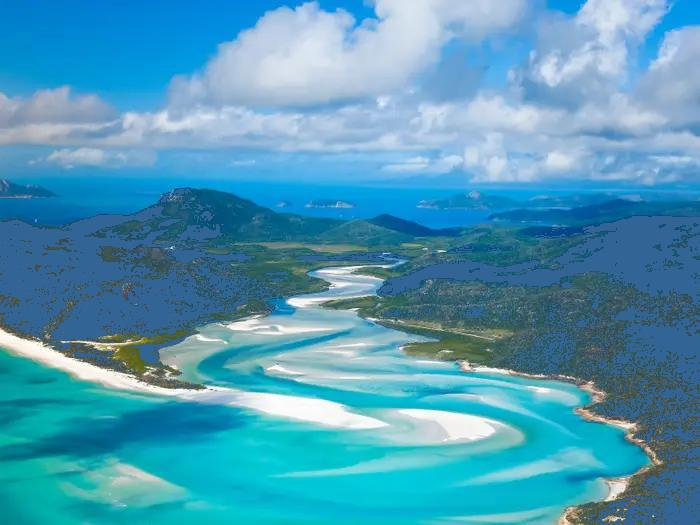

In [7]:
img_array_mod = img_array.copy()

img_array_red = img_array[0:Nrow,0:Ncol,0].copy()

for indrow in range(0,Nrow):
    for indcol in range(0,Ncol):
        r = img_array[indrow,indcol,0]
        g = img_array[indrow,indcol,1]
        b = img_array[indrow,indcol,2]
       
        lum = int(r) + int(g) + int(b)
        
        if lum < 200 :
            rnew = 50
            gnew = 100
            bnew = 150
        else:
            rnew = r
            gnew = g
            bnew = b
        
            
        img_array_mod[indrow,indcol,iRED] = rnew
        img_array_mod[indrow,indcol,iGREEN] = gnew
        img_array_mod[indrow,indcol,iBLUE] = bnew

image_new = PILimg.fromarray(img_array_mod,mode='RGB')
image_new.save("image_new.jpg")
display(Image(filename='./image.jpg', embed=True))
display(Image(filename='./image_new.jpg', embed=True))

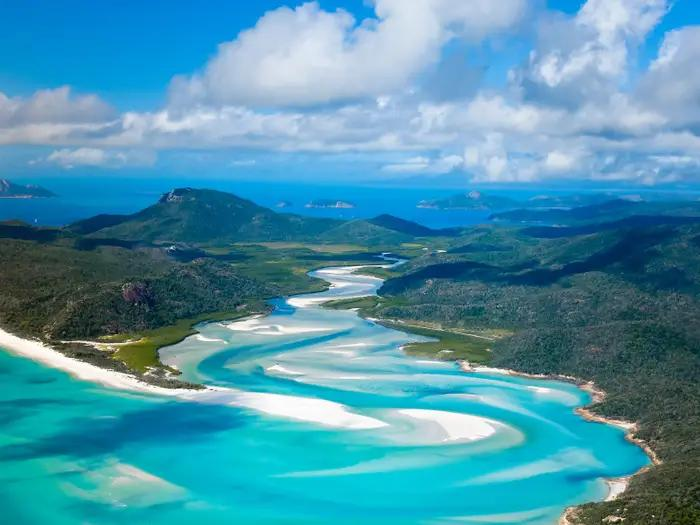

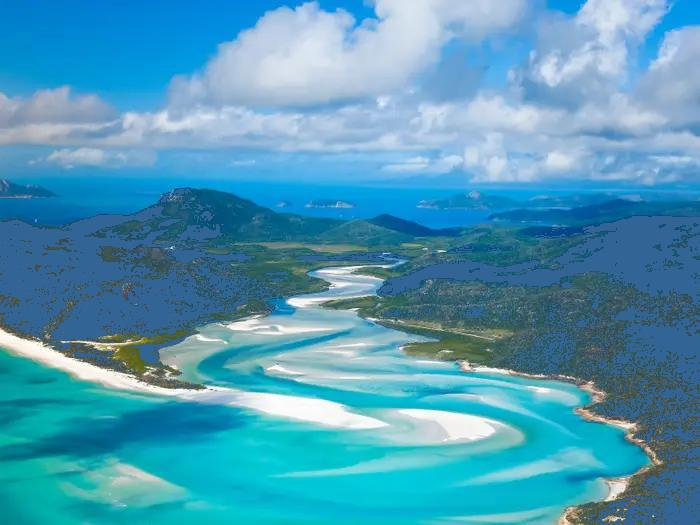

In [8]:
image_new = PILimg.fromarray(img_array_mod,mode='RGB')
image_new.save("image_new.jpg")
display(Image(filename='./image.jpg', embed=True))
display(Image(filename='./image_new.jpg', embed=True))

# Algorithm 2

Per pixel: 
- if the green value is less than the blue value, zero both and leave only the red channel
- if not, don't change any value

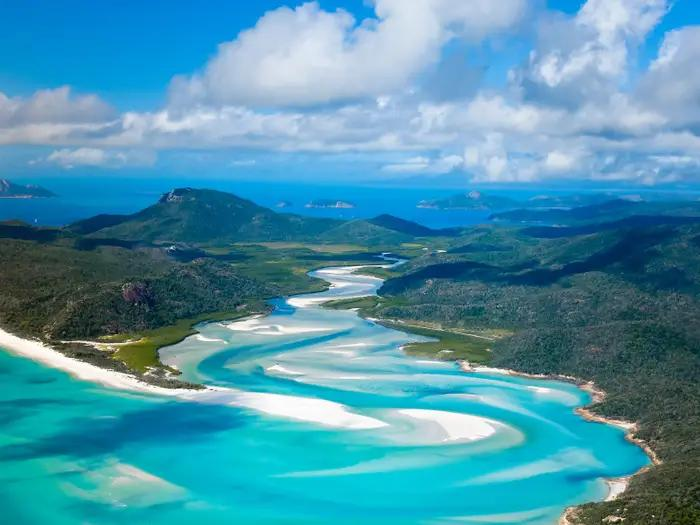

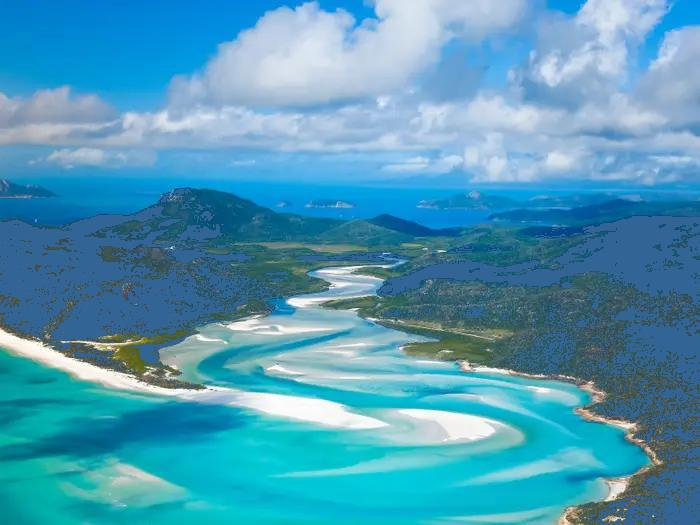

In [9]:
img_array_mod = img_array.copy()

img_array_red = img_array[0:Nrow,0:Ncol,0].copy()

for indrow in range(0,Nrow):
    for indcol in range(0,Ncol):
        r = img_array[indrow,indcol,0]
        g = img_array[indrow,indcol,1]
        b = img_array[indrow,indcol,2]
        
        if g < b:
            rnew = r
            gnew = 0
            bnew = 0
        else:
            rnew = r
            gnew = g
            bnew = b
                   
        img_array_mod[indrow,indcol,iRED] = rnew
        img_array_mod[indrow,indcol,iGREEN] = gnew
        img_array_mod[indrow,indcol,iBLUE] = bnew

image_new = PILimg.fromarray(img_array_mod,mode='RGB')
image_new.save("image_new.jpg")
display(Image(filename='./image.jpg', embed=True))
display(Image(filename='./image_new.jpg', embed=True))

## compare between channels

per pixelo: if green value is less than blue, zero out green and blue but leave red.
Otherwise, don't modify pixel colo.

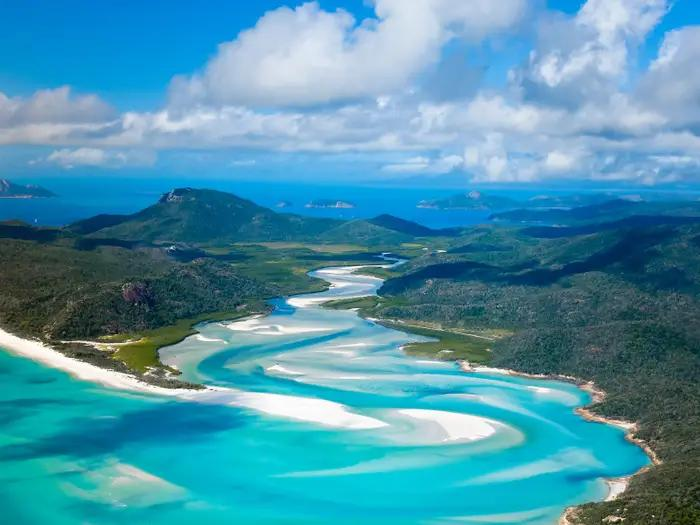

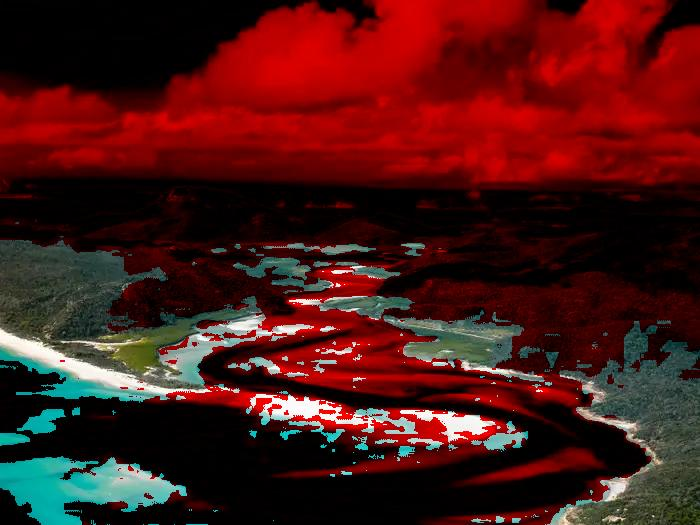

In [10]:
img_array_mod = img_array.copy()

img_array_red = img_array[0:Nrow,0:Ncol,0].copy()

for indrow in range(0,Nrow):
    for indcol in range(0,Ncol):
        r = img_array[indrow,indcol,0]
        g = img_array[indrow,indcol,1]
        b = img_array[indrow,indcol,2]
        
        if g < b:
            rnew = r
            gnew = 0
            bnew = 0
        else:
            rnew = r
            gnew = g
            bnew = b
                   
        img_array_mod[indrow,indcol,iRED] = rnew
        img_array_mod[indrow,indcol,iGREEN] = gnew
        img_array_mod[indrow,indcol,iBLUE] = bnew

image_new = PILimg.fromarray(img_array_mod,mode='RGB')
image_new.save("image_new.jpg")
display(Image(filename='./image.jpg', embed=True))
display(Image(filename='./image_new.jpg', embed=True))

# Mixing 2 images

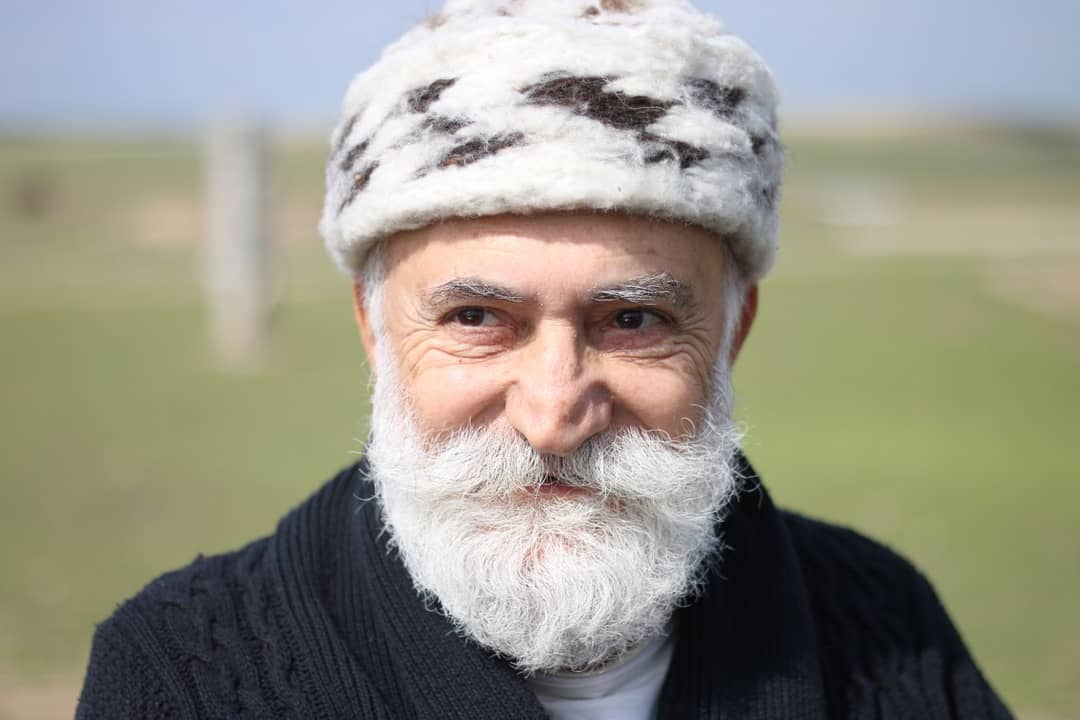

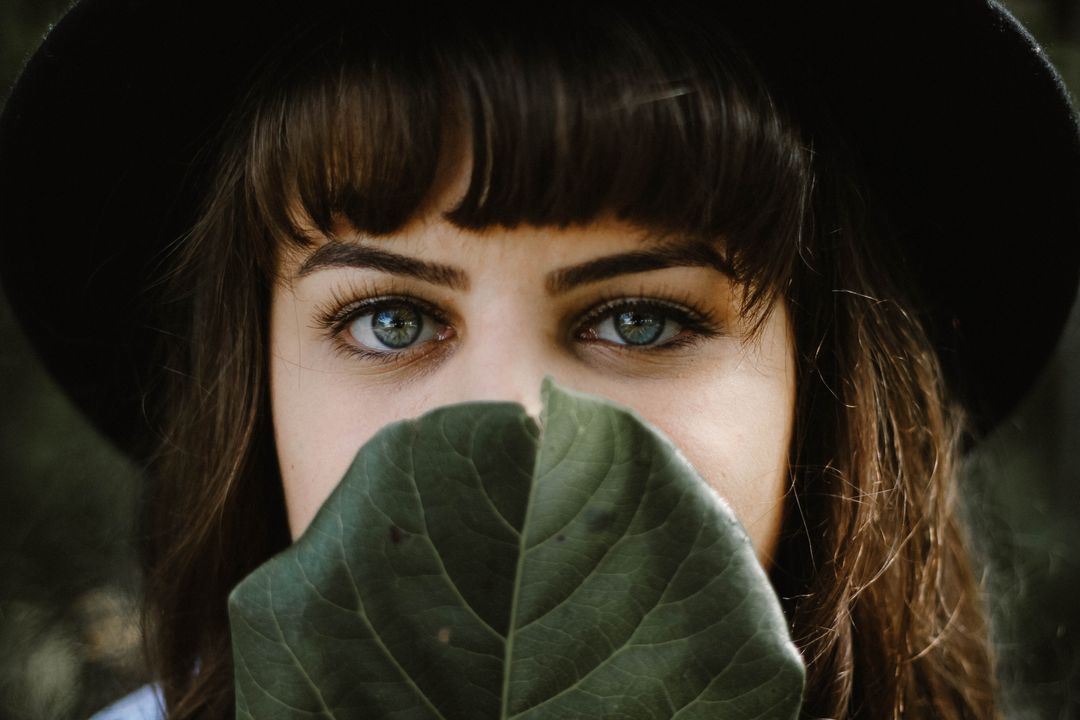

In [11]:
img1 = PILimg.open('./oldmanhat.jpg')
img2 = PILimg.open('./womanleaf.jpg')
img_array1 = np.array(img1)
img_array2 = np.array(img2)


Nlay = img_array1.shape[2]
Ncol = img_array1.shape[1]
Nrow = img_array1.shape[0]

display(Image(filename='./oldmanhat.jpg', embed=True))
display(Image(filename='./womanleaf.jpg', embed=True))

## Algorithm 3a

Per pixel:
- for r,g,b, determine which value is higher between these images
- higher color wins, independent of other colors

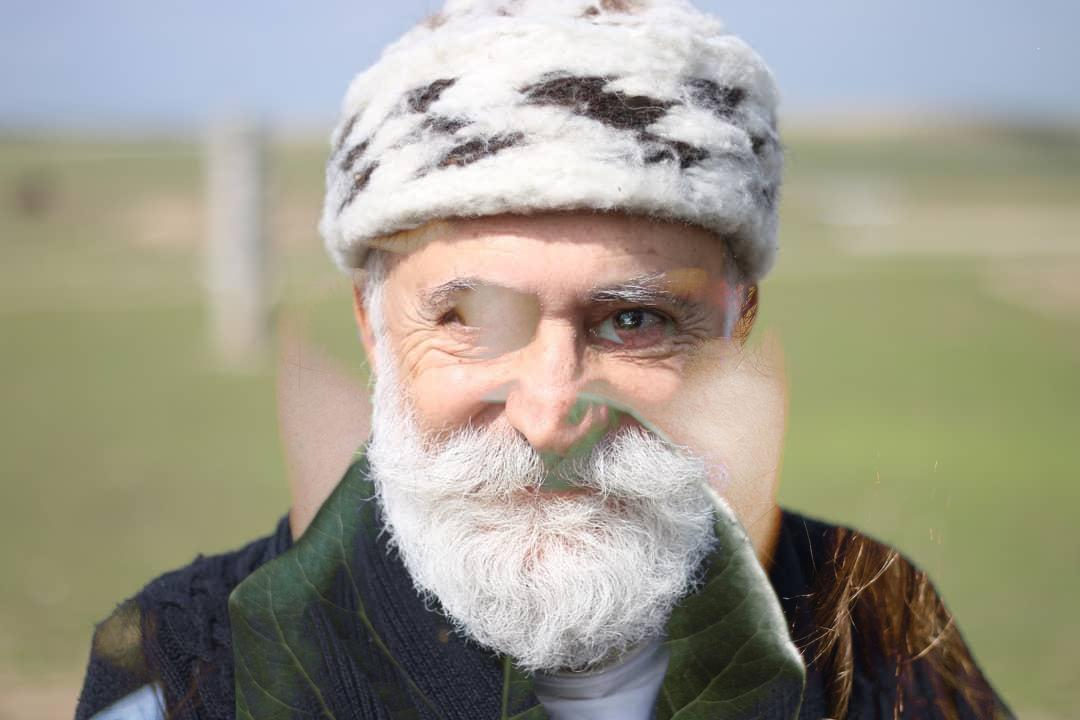

In [12]:
img_array_mod = np.array(img1).copy()

for indrow in range(0,Nrow):
    for indcol in range(0,Ncol):
        r1 = img_array1[indrow,indcol,0]
        g1 = img_array1[indrow,indcol,1]
        b1 = img_array1[indrow,indcol,2]

        r2 = img_array2[indrow,indcol,0]
        g2 = img_array2[indrow,indcol,1]
        b2 = img_array2[indrow,indcol,2]

        #higher value wins
        if r1 > r2:
            rnew = r1
        else:
            rnew = r2
            
        if g1 > g2:
            gnew = g1
        else:
            gnew = g2
            
        if b1 > b2:
            bnew = b1
        else:
            bnew = b2

        
        img_array_mod[indrow,indcol,iRED] = rnew
        img_array_mod[indrow,indcol,iGREEN] = gnew
        img_array_mod[indrow,indcol,iBLUE] = bnew

image_new = PILimg.fromarray(img_array_mod)
image_new.save("image_new.jpg")
display(Image(filename='./image_new.jpg', embed=True))

## Algorithm 3b

Per pixel:
- for r,g,b, determine which value is higher between these images
- lower color wins, independent of other colors

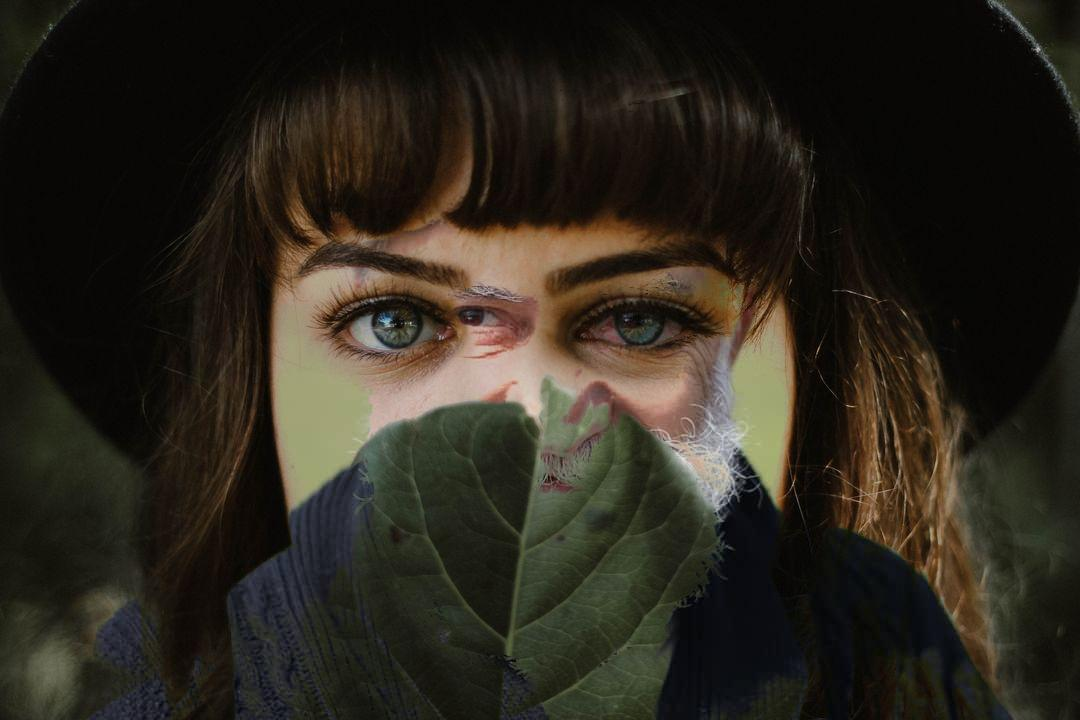

In [13]:
img_array_mod = np.array(img1).copy()

for indrow in range(0,Nrow):
    for indcol in range(0,Ncol):
        r1 = img_array1[indrow,indcol,0]
        g1 = img_array1[indrow,indcol,1]
        b1 = img_array1[indrow,indcol,2]

        r2 = img_array2[indrow,indcol,0]
        g2 = img_array2[indrow,indcol,1]
        b2 = img_array2[indrow,indcol,2]

        #lower value wins
        if r1 < r2:
            rnew = r1
        else:
            rnew = r2
            
        if g1 < g2:
            gnew = g1
        else:
            gnew = g2
            
        if b1 < b2:
            bnew = b1
        else:
            bnew = b2

        
        img_array_mod[indrow,indcol,iRED] = rnew
        img_array_mod[indrow,indcol,iGREEN] = gnew
        img_array_mod[indrow,indcol,iBLUE] = bnew

image_new = PILimg.fromarray(img_array_mod)
image_new.save("image_new.jpg")
display(Image(filename='./image_new.jpg', embed=True))

## Algorithm 4

Per pixel:
- determine if r,g, or b value is highest for each image independently
- use these to mix images

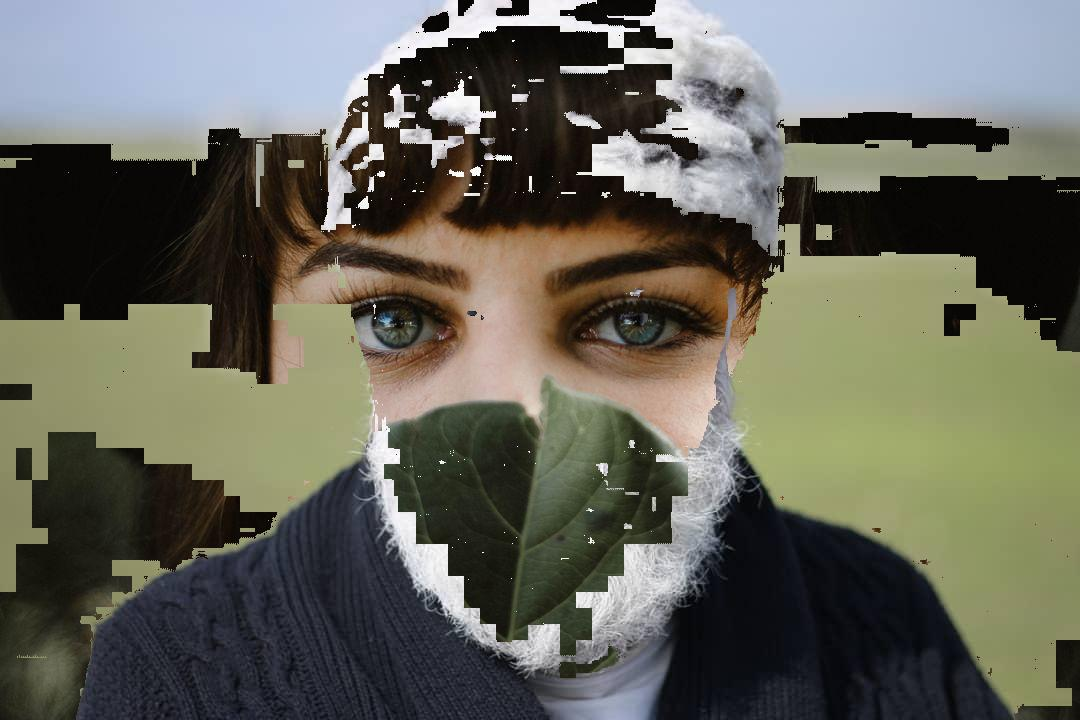

In [14]:
img_array_mod = np.array(img1).copy()

for indrow in range(0,Nrow):
    for indcol in range(0,Ncol):
        r1 = img_array1[indrow,indcol,0]
        g1 = img_array1[indrow,indcol,1]
        b1 = img_array1[indrow,indcol,2]

        r2 = img_array2[indrow,indcol,0]
        g2 = img_array2[indrow,indcol,1]
        b2 = img_array2[indrow,indcol,2]

        # sort 
        if r1 > g1:
            if r1 > b1:
                win1 = 'red'
            else:
                win1 = 'blue'
        else:
            if g1 > b1:
                win1 = 'green'
            else:
                win1 = 'blue'

        if r2 > g2:
            if r2 > b2:
                win2 = 'red'
            else:
                win2 = 'blue'
        else:
            if g2 > b2:
                win2 = 'green'
            else:
                win2 = 'blue'
        
        
        # if red is the dominant color in image 1, replace all colors for that pixel with the corresponding pixel (r,g,b) from image 2
        if win1 == 'red':
            img_array_mod[indrow,indcol,0] = r2
            img_array_mod[indrow,indcol,1] = g2
            img_array_mod[indrow,indcol,2] = b2

image_new = PILimg.fromarray(img_array_mod)
image_new.save("image_new.jpg")
#display(Image(filename='./image.jpg', embed=True))
display(Image(filename='./image_new.jpg', embed=True))